# Double descent — book graphics 3: deep double descent (ResNet18 / CIFAR-10)

Book versions of the model-wise and epoch-wise double descent plots from Nakkiran et al., *Deep Double Descent* (arXiv:1912.02292), using the authors' released run data (`dd_cifar10-resnet18k-50k-adam_*`: ResNet18 width k = 1…64, CIFAR-10 with data augmentation, Adam lr 1e-4, 4K epochs; three label-noise levels 0 / 10 / 20 %).

Note: Figure 1 of the paper reports test error against the *noisy* test labels; this data (like Figs 4b, 9, 10a) is clean-label error. `NOISY_LABEL_ERROR = True` rescales to the Figure-1 convention.

Exports (test error and train error for each):

- **Model-wise** — error vs width k, one curve per epoch (log-spaced), colored by log-epoch
- **Epoch-wise** — error vs epoch (log x), one curve per width (log-spaced), colored linearly by k
- standalone colorbars for epoch and width


## 1. Config

In [1]:
import pickle
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import MultipleLocator, LogLocator, FixedLocator, NullFormatter

# ── Book palette ───────────────────────────────────────────────────────────
CHILL_BROWN = '#948979'
LT_BLUE     = '#5badb6'
ORANGE      = '#eb8423'
GREEN       = '#419c52'
BLUE        = '#236c94'
RED         = '#d73b2f'
PINK        = '#ed5e78'
AXIS_COLOR  = CHILL_BROWN

def make_book_viridis(end_color='#fcc947', blend_start=0.6, n=256):
    """viridis whose top end bends smoothly into `end_color` instead of viridis's yellow."""
    base = mpl.colormaps['viridis']
    t = np.linspace(0, 1, n)
    cols = base(t)[:, :3]
    delta = np.array(mpl.colors.to_rgb(end_color)) - cols[-1]
    w = np.clip((t - blend_start) / (1 - blend_start), 0, 1)
    w = w * w * (3 - 2 * w)
    return mpl.colors.ListedColormap(np.clip(cols + w[:, None] * delta[None, :], 0, 1), name='book_viridis')

CMAP = make_book_viridis('#fcc947', blend_start=0.6)

# ── Data ───────────────────────────────────────────────────────────────────
DATA_DIR    = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/hackin')
MLIST_FILE  = DATA_DIR / 'dd_cifar10-resnet18k-50k-adam_Mlist'
NOISE_LEVELS = [0.0, 0.1, 0.2]          # order of the three entries in Mlist
NOISE       = 0.2                       # which one to plot
NOISY_LABEL_ERROR = False               # True = rescale to error vs noisy labels (paper Fig 1 convention)
N_CLASSES   = 10

# ── Model-wise plot (error vs width, one curve per epoch) ──────────────────
MW_N_EPOCHS     = 40                    # number of log-spaced epochs to draw
MW_EPOCH_RANGE  = (1, 3999)
MW_EPOCH_COLOR_REVERSED = False          # True: epoch 1 = gold end, epoch 4K = purple end (like the paper's Fig 1)
MW_LINEWIDTH    = 1.0
MW_XTICKS       = [1, 16, 32, 48, 64]
MW_SHOW_FINAL   = False                 # draw the final-epoch curve on top in MW_FINAL_COLOR
MW_FINAL_COLOR  = CHILL_BROWN
MW_FINAL_LINEWIDTH = 1.5

# ── Epoch-wise plot (error vs epoch, one curve per width) ──────────────────
EW_WIDTHS       = [1, 2, 3, 4, 6, 8, 11, 16, 23, 32, 45, 64]   # log-spaced widths; e.g. list(range(4, 65, 4))
EW_WIDTH_COLOR  = 'linear'              # 'linear' or 'log' mapping of k onto the colormap
EW_LINEWIDTH    = 1.0
EW_XTICKS       = [1, 10, 100, 1000]

# ── Axes / styling ─────────────────────────────────────────────────────────
AX_WIDTH_IN     = 8.0
AX_HEIGHT_IN    = 2.0
MARGIN_IN       = 0.6
AXIS_LINEWIDTH  = 1.0
FONTSIZE        = 15
YLIM_TEST       = (0.15, 0.7)           # None = auto
YLIM_TRAIN      = (0.0, 0.9)            # None = auto
Y_TICK_STEP     = 0.1
SPINES          = 'lb'
SHOW_TICKS      = True
SHOW_AXIS_LABELS = False                # x/y axis labels (you may prefer to set these in Illustrator)
TRANSPARENT     = True

# ── Colorbar export ────────────────────────────────────────────────────────
CBAR_SIZE_IN    = (0.18, AX_HEIGHT_IN)
CBAR_EPOCH_TICKS = [1, 10, 100, 1000]
CBAR_WIDTH_TICKS = [1, 16, 32, 48, 64]

# ── Fonts: LaTeX / Computer Modern look ────────────────────────────────────
USE_TEX = True
plt.rcParams['font.family']  = 'serif'
plt.rcParams['font.serif']   = ['cmr10', 'Computer Modern Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['text.usetex']  = USE_TEX
plt.rcParams['svg.fonttype'] = 'none'

# ── Output ─────────────────────────────────────────────────────────────────
OUT_DIR = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/deep_double_descent')
SAVE    = True
OUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Load data

In [2]:
with open(MLIST_FILE, 'rb') as fh:
    Mlist = pickle.load(fh)
run = Mlist[NOISE_LEVELS.index(NOISE)]

test_err  = run['Test Error']    # (64 widths, 3999 epochs), clean-label
train_err = run['Train Error']
n_widths, n_epochs = test_err.shape
widths = np.arange(1, n_widths + 1)
epochs = np.arange(1, n_epochs + 1)

if NOISY_LABEL_ERROR:
    # P(pred != noisy label) when a label is replaced w.p. p by a uniformly random *incorrect* class
    p = NOISE
    test_err = (1 - p) * test_err + p * (1 - test_err / (N_CLASSES - 1))

print(f'noise={NOISE:.0%}  widths={n_widths}  epochs={n_epochs}')
print(f'test error  final: k=1 {test_err[0,-1]:.3f}  k=64 {test_err[-1,-1]:.3f}   min over all {test_err.min():.3f}')
print(f'train error final: k=1 {train_err[0,-1]:.3f}  k=64 {train_err[-1,-1]:.4f}')


noise=20%  widths=64  epochs=3999
test error  final: k=1 0.423  k=64 0.196   min over all 0.172
train error final: k=1 0.537  k=64 0.0006


## 3. Renderers

In [3]:
def exact_axes(width_in, height_in, margin=MARGIN_IN):
    fig = plt.figure(figsize=(width_in + 2 * margin, height_in + 2 * margin))
    ax = fig.add_axes([margin / fig.get_figwidth(), margin / fig.get_figheight(),
                       width_in / fig.get_figwidth(), height_in / fig.get_figheight()])
    return fig, ax

def style_ax(ax, color=AXIS_COLOR):
    if SPINES == 'lb':
        ax.spines[['top', 'right']].set_visible(False)
    ax.spines[:].set_color(color)
    ax.spines[:].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(colors=color, labelsize=FONTSIZE, width=AXIS_LINEWIDTH, which='both')
    ax.xaxis.label.set_color(color)
    ax.yaxis.label.set_color(color)
    if not SHOW_TICKS:
        ax.set_xticks([]); ax.set_yticks([])

def set_ylim(ax, ylim, data):
    if ylim is None:
        lo, hi = np.nanmin(data), np.nanmax(data)
        ylim = (lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
    ax.set_ylim(*ylim)
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP))

# ── epoch colouring (log) ──────────────────────────────────────────────────
epoch_norm = mpl.colors.LogNorm(vmin=MW_EPOCH_RANGE[0], vmax=MW_EPOCH_RANGE[1])
def epoch_color(e):
    t = epoch_norm(e)
    return CMAP(1 - t if MW_EPOCH_COLOR_REVERSED else t)

mw_epochs = np.unique(np.round(np.logspace(np.log10(MW_EPOCH_RANGE[0]), np.log10(MW_EPOCH_RANGE[1]), MW_N_EPOCHS)).astype(int))

# ── width colouring ────────────────────────────────────────────────────────
def width_t(k):
    if EW_WIDTH_COLOR == 'log':
        return np.log(k) / np.log(n_widths)
    return (k - 1) / (n_widths - 1)
def width_color(k):
    return CMAP(width_t(k))

def draw_modelwise(ax, err, ylim):
    """error vs width, one curve per log-spaced epoch."""
    for e in mw_epochs:
        ax.plot(widths, err[:, e - 1], color=epoch_color(e), lw=MW_LINEWIDTH, zorder=2, solid_capstyle='round')
    if MW_SHOW_FINAL:
        ax.plot(widths, err[:, -1], color=MW_FINAL_COLOR, lw=MW_FINAL_LINEWIDTH, zorder=3)
    ax.set_xlim(widths[0], widths[-1])
    ax.set_xticks(MW_XTICKS)
    set_ylim(ax, ylim, err[:, mw_epochs - 1])
    if SHOW_AXIS_LABELS:
        ax.set_xlabel('ResNet18 width parameter $k$', fontsize=FONTSIZE)
        ax.set_ylabel('error', fontsize=FONTSIZE)
    style_ax(ax)

def draw_epochwise(ax, err, ylim):
    """error vs epoch (log x), one curve per selected width."""
    for k in EW_WIDTHS:
        ax.plot(epochs, err[k - 1], color=width_color(k), lw=EW_LINEWIDTH, zorder=2, solid_capstyle='round')
    ax.set_xscale('log')
    ax.set_xlim(epochs[0], epochs[-1])
    ax.xaxis.set_major_locator(FixedLocator(EW_XTICKS))
    ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10), numticks=50))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xticklabels([str(t) for t in EW_XTICKS])
    set_ylim(ax, ylim, err[np.array(EW_WIDTHS) - 1])
    if SHOW_AXIS_LABELS:
        ax.set_xlabel('epoch', fontsize=FONTSIZE)
        ax.set_ylabel('error', fontsize=FONTSIZE)
    style_ax(ax)

def figure(draw, err, ylim):
    fig, ax = exact_axes(AX_WIDTH_IN, AX_HEIGHT_IN)
    draw(ax, err, ylim)
    return fig, ax

def _cbar(cmap, norm, ticks, label, ticklabels=None):
    w, h = CBAR_SIZE_IN
    fig, ax = exact_axes(w, h)
    cb = mpl.colorbar.ColorbarBase(ax, cmap=cmap, norm=norm, orientation='vertical', ticks=ticks)
    cb.outline.set_edgecolor(AXIS_COLOR); cb.outline.set_linewidth(AXIS_LINEWIDTH)
    cb.ax.tick_params(colors=AXIS_COLOR, labelsize=FONTSIZE, width=AXIS_LINEWIDTH, which='both')
    cb.ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    if ticklabels is not None:
        cb.ax.set_yticklabels(ticklabels)
    cb.set_label(label, color=AXIS_COLOR, fontsize=FONTSIZE, rotation=90, labelpad=6)
    return fig, ax

def colorbar_epoch():
    cmap = CMAP.reversed() if MW_EPOCH_COLOR_REVERSED else CMAP
    return _cbar(cmap, epoch_norm, CBAR_EPOCH_TICKS, 'epoch', [str(t) for t in CBAR_EPOCH_TICKS])

def colorbar_width():
    if EW_WIDTH_COLOR == 'log':
        norm = mpl.colors.LogNorm(vmin=1, vmax=n_widths)
    else:
        norm = mpl.colors.Normalize(vmin=1, vmax=n_widths)
    return _cbar(CMAP, norm, CBAR_WIDTH_TICKS, 'width $k$', [str(t) for t in CBAR_WIDTH_TICKS])


## 4. Preview

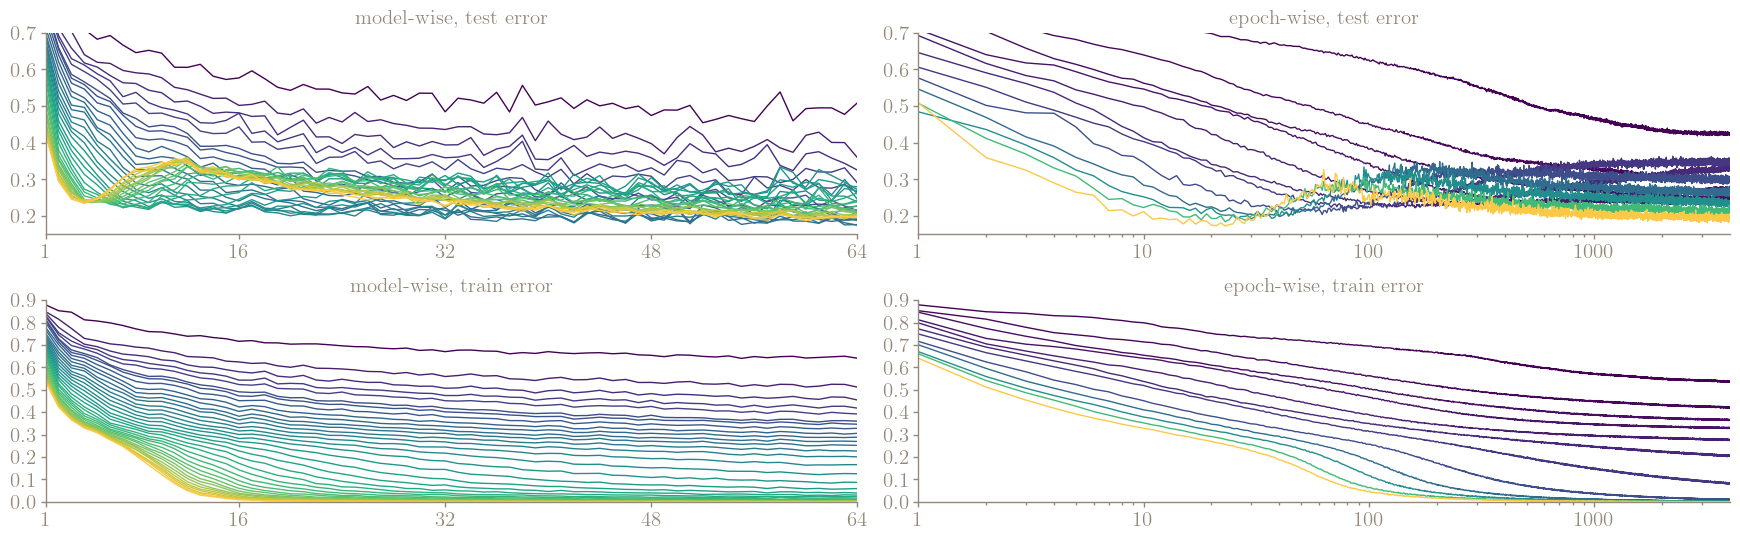

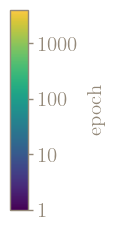

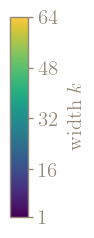

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(2 * AX_WIDTH_IN + 1.5, 2 * AX_HEIGHT_IN + 1.5))
draw_modelwise(axes[0, 0], test_err,  YLIM_TEST);  axes[0, 0].set_title('model-wise, test error',  color=AXIS_COLOR, fontsize=FONTSIZE)
draw_epochwise(axes[0, 1], test_err,  YLIM_TEST);  axes[0, 1].set_title('epoch-wise, test error',  color=AXIS_COLOR, fontsize=FONTSIZE)
draw_modelwise(axes[1, 0], train_err, YLIM_TRAIN); axes[1, 0].set_title('model-wise, train error', color=AXIS_COLOR, fontsize=FONTSIZE)
draw_epochwise(axes[1, 1], train_err, YLIM_TRAIN); axes[1, 1].set_title('epoch-wise, train error', color=AXIS_COLOR, fontsize=FONTSIZE)
plt.tight_layout(); plt.show()

fig, _ = colorbar_epoch(); plt.show()
fig, _ = colorbar_width(); plt.show()


## 5. Export

In [5]:
def save(fig, stem):
    for ext in ('svg', 'png'):
        fig.savefig(OUT_DIR / f'{stem}.{ext}', dpi=300, transparent=TRANSPARENT, bbox_inches='tight')
    plt.close(fig)

if SAVE:
    tag = f'noise{int(NOISE * 100):02d}' + ('_noisylabels' if NOISY_LABEL_ERROR else '')
    fig, _ = figure(draw_modelwise, test_err,  YLIM_TEST);  save(fig, f'modelwise_test_{tag}')
    fig, _ = figure(draw_modelwise, train_err, YLIM_TRAIN); save(fig, f'modelwise_train_{tag}')
    fig, _ = figure(draw_epochwise, test_err,  YLIM_TEST);  save(fig, f'epochwise_test_{tag}')
    fig, _ = figure(draw_epochwise, train_err, YLIM_TRAIN); save(fig, f'epochwise_train_{tag}')
    fig, _ = colorbar_epoch(); save(fig, 'colorbar_epoch')
    fig, _ = colorbar_width(); save(fig, 'colorbar_width')
    print('saved to', OUT_DIR)
    for p in sorted(OUT_DIR.glob('*.svg')):
        print('  ', p.name)


saved to /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/deep_double_descent
   colorbar_epoch.svg
   colorbar_width.svg
   epochwise_test_noise20.svg
   epochwise_train_noise20.svg
   modelwise_test_noise20.svg
   modelwise_train_noise20.svg
